# p2.6: Phase 1's teaching result on the two-mode student (11/25/26)

*Part of phase 2: `p2_summary.ipynb` (section 10) connects this notebook with p2.1-p2.5.*

Phase 1's teaching results came from a student that played by intuition alone. Phase 2 replaced it with the two-mode
student (`spec.STUDENT`: AND-OR deliberation, flat planning and intuition drawn per move, on a start of two networks
with 2 lane blocks each). Do phase 1's results still hold? Phase 1 had two:
- **bayes4 beats no teacher at every agency** (ΔA, how much a shown move teaches; the student's own play is 1), by
  0.20-0.30 moves / optimal at the end of the session.
- **Showing every move goes from harmful to the best help as ΔA rises**: +0.75 at ΔA 0.1, −0.61 at ΔA 1, overtaking
  bayes4 between ΔA 0.5 and 0.7.

**The runs** (`experiments/replication_queue.py`): phase 1's ×10 agency sweep played again, with the same teachers per
ΔA (bayes4 alone at 0; no teacher, bayes4, random 30% and random 100% at 1; bayes4 and the two randoms in between), 8
students per run and seeds 0-2. Two students:
- **two-mode**: today's fitted student (`--fitted`), runs `twomode_m10[_s<seed>]_agency<a>`;
- **intuition, new start**: phase 1's way of playing on today's start (`--fitted --student intuition`), runs
  `intuition_m10[_s<seed>]_agency<a>`. It tells the change of start apart from the change of play.

Phase 1's own runs are `aostart_free_m10[_s<seed>]_agency<a>`.

**The score** is phase 1's (`experiments/phase2_analysis.py`): the end test's moves / optimal, an unsolved puzzle
counted at its cap (10 × optimal), untaught and without giving up. Each teacher is compared with no teacher student by
student and pooled over seeds (24 students). No teacher runs only at ΔA 1, since it never sees a shown move. Tables:
`experiments/replication_analysis.py` → `models/summary/replication_{twomode,intuition}.csv`, beside phase 1's
`ao10_agency_seeds.csv`.

In [1]:
import os
import sys
sys.path.insert(0, "..")
sys.path.insert(0, os.path.join("..", "experiments"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import phase2_analysis as p2
import replication_analysis as ra
from rushhour import analysis as an

INK, MUTED, RULE, GRID = "#1f1f1d", "#5f5e5a", "#b5b4ad", "#e6e5e0"
STUDENTS = {"phase 1": p2.SEEDS, "intuition, new start": ra.seeds("intuition"), "two-mode": ra.seeds("twomode")}
TABLES = {"phase 1": "ao10_agency_seeds.csv", "intuition, new start": "replication_intuition.csv",
          "two-mode": "replication_twomode.csv"}
S_COLORS = {"phase 1": "#8a8a85", "intuition, new start": "#2a78d6", "two-mode": "#e6550d"}
TEACHERS = {"bayes4": "bayes4", "random:0.3": "random 30%", "random:1.0": "random 100%"}
T_COLORS = {"bayes4": INK, "random:0.3": "#fdae6b", "random:1.0": "#e6550d"}
plt.rcParams.update({"font.size": 9, "axes.titlesize": 10, "axes.titlelocation": "left", "figure.dpi": 110,
                     "legend.frameon": False, "legend.fontsize": 8.5})


def tidy(ax, grid="y"):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(RULE)
    ax.tick_params(colors=MUTED)
    if grid:
        ax.grid(axis=grid, color=GRID, lw=0.8)
    ax.set_axisbelow(True)


tables = {s: pd.read_csv(os.path.join(p2.SUMMARY, f)) for s, f in TABLES.items()}

# no teacher: each test of the session, per student, averaged over the 8 students of a run and then over seeds
rows = []
for student, seeds in STUDENTS.items():
    for seed, pattern in seeds.items():
        e = an.entry(pattern.format(p2.NONE_AT), "none")
        for s, by_n in e["results"].items():
            for n, attempts in by_n.items():
                score, solved, solved_ratio = an.measures(attempts, e["config"])
                rows.append({"student": student, "seed": seed, "id": s, "trial": int(n) // 10, "score": score,
                             "solved": solved, "moves / optimal (solved)": solved_ratio})
untaught = pd.DataFrame(rows)
none_end = untaught[untaught.trial == untaught.trial.max()].groupby("student").score.mean()

## 1. Each teacher against no teacher

The end score's difference from no teacher (negative: the teacher helped), pooled over seeds 0-2, ± 1 SE across the
24 students.

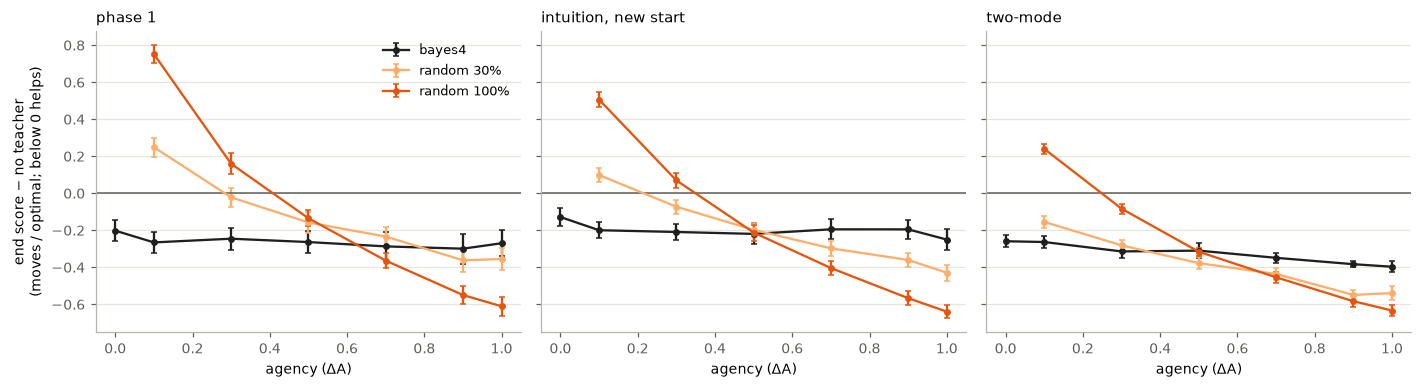

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, (student, t) in zip(axes, tables.items()):
    for teacher, label in TEACHERS.items():
        d = t[t.teacher == teacher].sort_values("agency")
        ax.errorbar(d.agency, d.pooled, yerr=d["pooled se"], fmt="o-", ms=3.5, capsize=2, color=T_COLORS[teacher],
                    label=label)
    ax.axhline(0, color=MUTED, lw=1)
    ax.set_title(student)
    ax.set_xlabel("agency (ΔA)")
    tidy(ax)
axes[0].set_ylabel("end score − no teacher\n(moves / optimal; below 0 helps)")
axes[0].legend()
plt.tight_layout()
plt.show()

side = None
for student, t in tables.items():
    t = t.assign(teacher=t.teacher.map(TEACHERS))
    t = t.set_index(["agency", "teacher"])[["pooled", "better"]].rename(
        columns={"pooled": (student, "− none"), "better": (student, "better")})
    side = t if side is None else side.join(t, how="outer")
side.columns = pd.MultiIndex.from_tuples(side.columns)
side.style.format("{:+.2f}", subset=[c for c in side.columns if c[1] == "− none"])

- **Both of phase 1's results hold for the two-mode student.**
  - bayes4 beats no teacher at every ΔA, by 0.26-0.40, for 23-24 of 24 students at each ΔA. Its gain grows with
    ΔA (−0.26 at ΔA 0 and 0.1, −0.40 at ΔA 1), where phase 1's stayed level at 0.20-0.30.
  - Showing every move goes from harmful at ΔA 0.1 (+0.24) to the best help at ΔA 1 (−0.63), and overtakes bayes4
    between ΔA 0.5 (−0.32 against −0.31, a tie) and 0.7 (−0.45 against −0.35), as in phase 1.
- **But showing moves stops hurting much sooner.** Showing every move costs the two-mode student +0.24 at ΔA 0.1,
  against +0.75 in phase 1. It already helps at ΔA 0.3 (−0.08, 15 of 24 students). Random 30% helps at every ΔA, even
  0.1 (−0.15), comes within 0.03 of bayes4 at ΔA 0.3 and beats it from 0.5 on (−0.38 against −0.31). In
  phase 1 random 30% hurt at 0.1 (+0.25) and only beat bayes4 from 0.9.
- **The intuition student on the new start lies between the two.** Showing every move costs it +0.51 at ΔA 0.1;
  random 30% hurts only at 0.1 (+0.10). bayes4 helps it a little less than in phase 1 (−0.13 to −0.25), for 17-20 of
  24 students. So the new start accounts for part of the shift and the two-mode play for the rest, in the same
  direction.
- **At ΔA 1 the three agree**: showing every move gives −0.61 to −0.64, random 30% −0.36 to −0.54.

## 2. The student no teacher meets

Each test of the no-teacher session (every 18 people's trials; 200 puzzles of 9-26 moves, played 3 times, untaught and
without giving up), averaged over the 8 students of each seed and the three seeds.

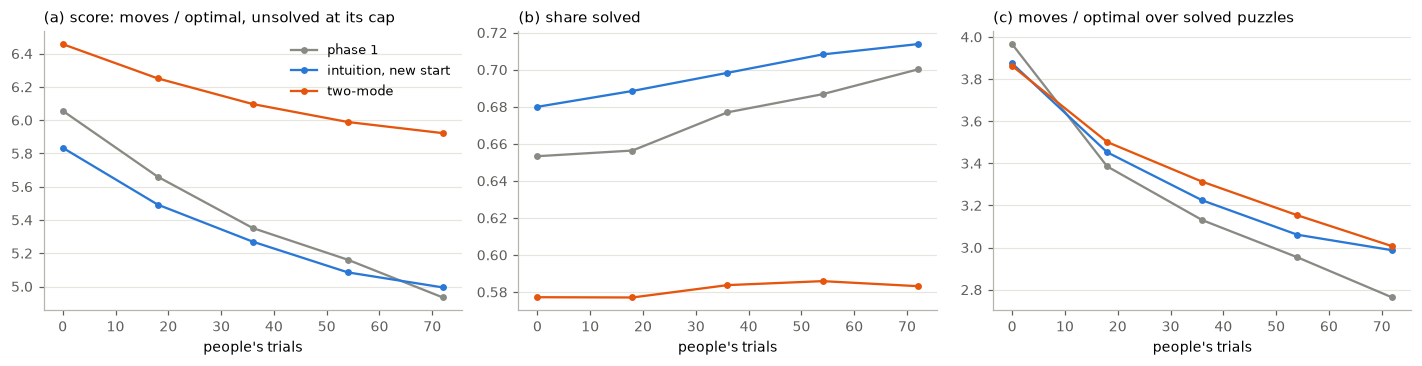

,score at start,score at end,gain,solved at start,solved at end
student,,,,,
phase 1,6.056,4.934,1.122,0.653,0.700
"intuition, new start",5.834,4.995,0.840,0.680,0.714
two-mode,6.457,5.922,0.535,0.577,0.583


In [3]:
curve = untaught.groupby(["student", "trial"])[["score", "solved", "moves / optimal (solved)"]].mean()
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for student in STUDENTS:
    d = curve.loc[student]
    for ax, col in zip(axes, d.columns):
        ax.plot(d.index, d[col], "o-", ms=3.5, color=S_COLORS[student], label=student)
for ax, title in zip(axes, ["(a) score: moves / optimal, unsolved at its cap", "(b) share solved",
                            "(c) moves / optimal over solved puzzles"]):
    ax.set_title(title)
    ax.set_xlabel("people's trials")
    tidy(ax)
axes[0].legend()
plt.tight_layout()
plt.show()
ends = curve.unstack("trial")
pd.DataFrame({"score at start": ends[("score", 0)], "score at end": ends[("score", 72)],
              "gain": ends[("score", 0)] - ends[("score", 72)], "solved at start": ends[("solved", 0)],
              "solved at end": ends[("solved", 72)]}).loc[list(STUDENTS)].round(3)

- **The two-mode student starts worse and gains less on this score.** Its test score goes from 6.46 to 5.92,
  a gain of 0.54, against 5.83 → 5.00 (0.84) for the intuition student on the same start and 6.06 → 4.93 (1.12) in
  phase 1.
- **The difference is the solve rate.** The two-mode student solves 58% of the test puzzles at the start and 58% at
  the end. The intuition students go from 65-68% to 70-71%. On the puzzles it solves, the two-mode student gets about
  as much more efficient as the others (about 3.9 → 3.0 moves / optimal, against 3.9 → 2.8-3.0), so its gain comes
  from efficiency, not from solving more. The unsolved puzzles count at 10 × optimal and dominate the score.
- **Why it solves fewer** is section 4: none of its modes, but its soft memory, which lets it loop on long puzzles.
  These tests reach 26 moves and allow up to 10 × optimal, longer than most of people's puzzles. The tracking check
  (p2_summary, section 9) found the same: untaught, the two-mode student solves 25% of 19-26-move puzzles against the
  intuition student's 38%.

So the two-mode student leaves a teacher more room (its untaught end score is 5.92 against 4.93-5.00), and gains less on
this score.

## 3. The effects relative to where each student ends

Since the two-mode student ends worse untaught, each effect divided by that student's untaught end score (seeds
pooled): the share of the end score a teacher removes or adds.

In [4]:
rel = {}
for student, t in tables.items():
    rel[student] = (t.set_index(["agency", "teacher"]).pooled / none_end[student]).rename(index=TEACHERS, level=1)
rel = pd.DataFrame(rel)
print("untaught end score:", none_end.loc[list(STUDENTS)].round(2).to_dict())
rel.style.format("{:+.1%}")

untaught end score: {'phase 1': 4.93, 'intuition, new start': 4.99, 'two-mode': 5.92}


- **Relative to its baseline, bayes4 helps the two-mode student about as much as it helped phase 1's student**:
  4-7% of the end score against 4-6%. The intuition student on the new start gains less (3-5%). The larger absolute
  effect in section 1 is mostly the weaker baseline.
- **Showing every move at low ΔA still hurts the two-mode student far less**: +4% at ΔA 0.1, against +10% for the
  intuition student on the same start and +15% in phase 1. This difference isn't the baseline.
- **At ΔA 1, showing every move helps all three by 11-13%.**

**A reading, not tested here:** a shown move costs the student the learning it would have had from its own play.
With random 100% at ΔA 0.1 it learns from only a tenth of the session's moves. The two-mode student's own play teaches
it least (gain 0.54 against 0.84 and 1.12, section 2), so it has the least to lose. Shown moves also lead to solved
attempts, which are the only attempts it learns from, and it solves fewest on its own.

## 4. Why the two-mode student solves fewer

*(`experiments/solve_rate.py` → `models/summary/solve_rate/attempts.csv`)* Seed 0's test puzzles (200 of 9-26 moves;
untaught, no giving up, a cap of 10 × optimal) played by three kinds of network: the start (16 attempts per puzzle),
and the 8 end-of-session students of each no-teacher run (2 attempts each). Each network plays five ways:
- the two-mode student's play, as the tests play it;
- the same without AND-OR, or without flat planning;
- intuition with the soft memory;
- phase 1's play: intuition with its hard memory (never back to one of the last 10 boards if it can avoid it).

In [5]:
from IPython.display import display

PLAYS = ["two-mode", "no AND-OR", "no flat", "intuition, soft memory", "intuition, hard memory"]
NETS = ["start", "after two-mode session", "after intuition session"]
sr = pd.read_csv(os.path.join(p2.SUMMARY, "solve_rate", "attempts.csv"))
sr["length"] = pd.cut(sr.distance, [0, 11, 16, 21, 26], labels=["9-11", "14-16", "19-21", "24-26"])
sr["new boards"] = sr.boards / (sr.moves + 1)
solved = sr.pivot_table(index="network", columns="play", values="solved").loc[NETS, PLAYS]
by_length = sr.pivot_table(index=["network", "length"], columns="play", values="solved", observed=True).loc[NETS, PLAYS]
looping = sr[~sr.solved].pivot_table(index="network", columns="play", values="new boards").loc[NETS, PLAYS]
efficiency = sr[sr.solved].assign(r=lambda d: d.moves / d.distance).pivot_table(
    index="network", columns="play", values="r").loc[NETS, PLAYS]
# the session's gain in solve rate, paired by puzzle (an attempt's seed // 1000 is its puzzle)
start = sr[sr.network == "start"].groupby(["play", sr.seed // 1000]).solved.mean()
gain = {}
for net in NETS[1:]:
    end = sr[sr.network == net].groupby(["play", sr.seed // 1000]).solved.mean()
    d = (end - start).groupby("play")
    gain[net] = d.mean().round(3).astype(str) + " ± " + (d.std() / np.sqrt(d.size())).round(3).astype(str)
display(solved.style.format("{:.3f}").set_caption("share solved"))
display(by_length.style.format("{:.3f}").set_caption("share solved, by length"))
display(looping.style.format("{:.2f}").set_caption("unsolved attempts: share of moves that reach a new board"))
display(efficiency.style.format("{:.2f}").set_caption("solved attempts: moves / optimal"))
pd.DataFrame(gain).T[PLAYS].style.set_caption("solve rate after the session − at the start, paired by puzzle (± SE)")

play,two-mode,no AND-OR,no flat,"intuition, soft memory","intuition, hard memory"
network,,,,,
start,0.567,0.570,0.543,0.540,0.668
after two-mode session,0.572,0.562,0.561,0.543,0.672
after intuition session,0.577,0.574,0.556,0.556,0.682


play,two-mode,no AND-OR,no flat,"intuition, soft memory","intuition, hard memory"
network,,,,,
start,0.46,0.48,0.47,0.49,0.70
after two-mode session,0.28,0.28,0.28,0.29,0.49
after intuition session,0.30,0.29,0.30,0.30,0.49


play,two-mode,no AND-OR,no flat,"intuition, soft memory","intuition, hard memory"
network,,,,,
start,3.93,4.01,3.88,3.94,3.89
after two-mode session,3.00,3.01,2.98,2.96,2.89
after intuition session,2.99,3.04,2.99,3.03,2.93


play,two-mode,no AND-OR,no flat,"intuition, soft memory","intuition, hard memory"
after two-mode session,0.005 ± 0.017,-0.008 ± 0.017,0.018 ± 0.016,0.004 ± 0.017,0.003 ± 0.016
after intuition session,0.01 ± 0.017,0.004 ± 0.018,0.013 ± 0.016,0.016 ± 0.017,0.014 ± 0.014


- **Memory, not planning, sets the level.** With the same network, phase 1's hard memory solves about 10 points
  more than the soft memory (0.67-0.68 against 0.54-0.58), and 15-17 points more on 19-26-move puzzles. AND-OR and
  flat planning together add only 2-3 points over intuition with the same soft memory. On the puzzles they solve, all
  five plays are equally efficient.
- **What fails is looping.** In unsolved attempts under the soft memory, 46-49% of moves reach a new board at the start
  and 28-30% after the session: about 60 distinct boards in 200 moves or more. Under the hard memory, 70% and 49%. As
  the policy sharpens with learning, it steers back to the same boards more often.
- **The network learns as well either way.** Played the same way, the networks trained in the two-mode session and in
  the intuition session solve within 1-2 points of each other.
- **The flat solve rate isn't the two-mode student's alone.** Paired by puzzle, every play's solve rate changes by only
  −0.01 to +0.02 over the session (SE about 0.016), the hard memory included. Learning trades puzzles: 14-16-move
  puzzles drop 5-7 points and 24-26-move ones rise 7-8. The intuition run at seed 0 gained as little in its own tests
  (+0.016); its larger pooled gain (section 2) comes from seeds 1 and 2.

**Is the soft memory too weak?** It was fitted (`experiments/fit_memory.py`) to people's returns to earlier boards on
solved attempts of 1.5-3 × optimal only, which can't see an attempt that fails. Below, all of people's attempts on
their 70 layouts, by length, against the fit's simulations (that fit's start network by intuition; cap 10 × optimal,
no giving up): the share of moves that return to an earlier board.

In [6]:
import fit_memory as fm

mv = fm._people()
att = mv.groupby(["who", "instance", "attempt"]).agg(n=("move", "size"), L=("optimal length", "first"),
                                                       solved=("solved", "first"),
                                                       returns=("board age", lambda a: a.notna().sum()))
att["ratio"] = att.n / att.L
sims = pd.read_csv(os.path.join(p2.SUMMARY, "memory_fit.csv"))
sims["returns"] = sims.ages.fillna("").map(lambda s: len(s.split()))
sims["ratio"] = sims.moves / sims.optimal
MEMORIES = {"beta 2, half-life 1": "soft (β 2, half-life 1)", "beta 2, half-life 8": "β 2, half-life 8",
            "hard, last 10 boards": "hard, last 10 boards", "no memory": "no memory"}
rows = []
for lo, hi in [(1.5, 3), (3, 5), (5, 8), (8, 10.01)]:
    p = att[att.ratio.between(lo, hi, inclusive="left")]
    row = {"attempt (× optimal)": f"{lo:g}-{min(hi, 10):g}", "people": p.returns.sum() / p.n.sum(),
           "people's attempts": len(p)}
    for key, label in MEMORIES.items():
        q = sims[(sims.condition == key) & sims.ratio.between(lo, hi, inclusive="left")]
        row[label] = q.returns.sum() / q.moves.sum()
    rows.append(row)
print(f"people solve {att.solved.mean():.0%} of their attempts (giving up counted as unsolved)")
pd.DataFrame(rows).set_index("attempt (× optimal)").style.format("{:.3f}").format("{:d}", subset=["people's attempts"])

people solve 70% of their attempts (giving up counted as unsolved)


,people,people's attempts,"soft (β 2, half-life 1)","β 2, half-life 8","hard, last 10 boards",no memory
attempt (× optimal),,,,,,
1.5-3,0.112,913,0.086,0.035,0.001,0.110
3-5,0.172,295,0.145,0.063,0.030,0.190
5-8,0.236,91,0.217,0.102,0.060,0.246
8-10,0.298,24,0.315,0.195,0.151,0.373


- **People loop as much as the soft memory does, even in their long attempts.** 17% of their moves return to an
  earlier board at 3-5 × optimal and 24% at 5-8 × (the soft memory: 15% and 22%; the hard memory: 3% and 6%). In their
  longest attempts, people revisit about as much as a student with no memory.
- **So the soft memory stays.** A stronger memory would solve more by forcing the student onto new boards, which
  people don't do. What people have and the student lacks is a way out from where they are: the mid-puzzle skill gap
  (`MODEL.md`, premise 12: people make 48-59% optimal moves 7-9 from the goal, the student 33-36%). On these tests
  it shows as looping, most on the 19-26-move puzzles, which are longer than most of people's.
- **Caveats.** People's restarts take them back to the start board and may count as returns. Only 24 of people's
  attempts run past 8 × optimal. People give up, and solve 70% of attempts counting that, against the student's
  58% without giving up.

## 5. bayes4's θ for the two-mode student

bayes4's θ (0.45) and its model of the student come from phase 1 and weren't refitted for this student. Phase 1's
check repeated (`replication_queue.py --theta`): bayes4 at θ 0.25, 0.75 and 0.9 beside 0.45, at ΔA 0, 0.3 and 1, seed
0 (8 students), each against no teacher. `replication_theta.csv`, beside phase 1's `bayes4_theta.csv`.

In [7]:
th = pd.concat({"phase 1": pd.read_csv(os.path.join(p2.SUMMARY, "bayes4_theta.csv")),
                "two-mode": pd.read_csv(os.path.join(p2.SUMMARY, "replication_theta.csv"))}, names=["student"])
th = th.reset_index("student").pivot_table(index=["agency", "theta"], columns="student", values=["vs none", "shown"])
th.columns = [f"{s}: {m}" for m, s in th.columns]
th.index = pd.MultiIndex.from_tuples([(f"{a:g}", f"{t:g}") for a, t in th.index], names=["agency", "theta"])
# random 30% at seed 0, for the same spend
r30 = {s: tables[s].set_index(["agency", "teacher"])["seed 0"].xs("random:0.3", level="teacher")
       for s in ("phase 1", "two-mode")}
print("random 30% at seed 0 (vs none):", {s: r.loc[[0.3, 1.0]].round(3).to_dict() for s, r in r30.items()})
cols = ["phase 1: vs none", "two-mode: vs none", "phase 1: shown", "two-mode: shown"]
th[cols].style.format("{:+.3f}", subset=cols[:2]).format("{:.1%}", subset=cols[2:])

random 30% at seed 0 (vs none): {'phase 1': {0.3: -0.189, 1.0: -0.556}, 'two-mode': {0.3: -0.247, 1.0: -0.448}}


- **The same shape as phase 1, so θ 0.45 stays.**
  - θ 0.25 and 0.45 do alike at every ΔA (−0.19 to −0.31), showing 5-7% of moves.
  - θ 0.75 shows 12-15%. It is worse at ΔA 0 (−0.03), as good at 0.3, and better at 1 (−0.45 against −0.31).
  - θ 0.9 shows 30-34%. It hurts at ΔA 0 (+0.37), does nothing at 0.3, and does best at 1 (−0.48).

  Phase 1 found the same. Recalibrating θ doesn't make the dilemma steeper again.
- **At the same spend, random does better than bayes4 at middling ΔA.** bayes4 at θ 0.9 shows about as many moves as
  random 30%, but at ΔA 0.3 it ends no better than no teacher (+0.01), while random 30% helps (−0.25; seed 0). At ΔA 1
  they are about even (−0.48 against −0.45). Phase 1 shows the same at ΔA 0.3, less strongly (−0.12 against −0.19).
  **A reading:** bayes4 shows runs of moves on the puzzles it expects the student to fail, so whole stretches of those
  puzzles teach only at ΔA, while random spreads the same spend thinly.

## 6. What this means

- **Phase 1's conclusions carry over to a student that plans**: bayes4 helps at every ΔA, and how much showing moves
  helps depends on ΔA, from harmful to the best help.
- **Where the balance tips depends on the student.** The two-mode student crosses from harm to help between ΔA 0.1
  and 0.3, not 0.3 and 0.5. Random 30% beats bayes4 from ΔA 0.5 on (phase 1: 0.9). A student that learns less from its own
  play, or solves less on its own, makes help cheaper. The assistance dilemma's answer moves with the learner, not
  only with ΔA.
- **bayes4's θ isn't why the dilemma is flatter** (section 5): refitted, 0.45 is still as good as any at low ΔA, as in
  phase 1. What changed is the cost of showing moves at low ΔA. bayes4 shows 6-7% of moves to the two-mode student,
  against 4.5-5%, though its solve chance is too flat across this protocol's lengths (section 9 of p2_summary).
- **The two-mode student's lower solve rate is its soft memory meeting the mid-puzzle skill gap** (section 4). It loops
  on long puzzles, but people loop as much. The memory stays as fitted.
- **A caveat on the protocol:** the tests' puzzles of 19-26 moves are beyond most of people's data. Much of what
  separates the students here is what they do on those puzzles, where the two-mode student isn't fitted to people.